## T05 - Simulación Multiactivo

#### Simulación de Procesos Financieros

José Armando Melchor Soto
 | 11/11/2026


---

#### Libraries 

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

from warnings import filterwarnings
filterwarnings('ignore')


---

#### Parámetros

In [2]:
T = 1
M = 10_000
V0 = 100_000

tickers_A = ["NVDA", "BIMBOA.MX", "CEMEXCPO.MX", "AZN", "MXN=X"]
tickers_B = ["AAPL", "MSFT", "NVDA"]

escenarios_A = {
    "A": np.array([1, 0, 0, 0]),
    "B": np.array([0.25, 0.25, 0.25, 0.25]),
    "C": np.array([0.10, 0.20, 0.30, 0.40])
}

escenarios_B = {
    "A": np.array([1, 0, 0]),
    "B": np.array([0.33, 0.33, 0.34]),
    "C": np.array([0.2, 0.2, 0.6])
}


---

#### Functions

In [3]:
def obtener_datos(tickers):
    """Descarga los precios históricos y calcula los parámetros de cada activo.

    Args:
        tickers: Lista de símbolos de los activos.

    Returns:
        prices: Precios históricos de cierre.
        mu: Rendimiento promedio anualizado.
        sigma: Volatilidad anualizada.
        R: Matriz de correlaciones de los rendimientos.
    """
    prices = yf.download(tickers, period="3y", auto_adjust=True, progress=False)["Close"]
    prices = prices.reindex(columns=tickers).ffill().dropna()

    rend = np.log(prices / prices.shift(1)).dropna()
    mu = rend.mean().values * 252
    sigma = rend.std().values * np.sqrt(252)
    R = rend.corr()

    return prices, mu, sigma, R


def generar_epsilon(n, M, semilla=0):
    """Genera normales estándar independientes.

    Args:
        n: Número de activos.
        M: Número de simulaciones.
        semilla: Semilla para reproducir los mismos shocks.

    Returns:
        epsilon: Matriz de shocks independientes (M x n).
    """
    np.random.seed(semilla)
    epsilon = np.random.normal(0, 1, (M, n))

    return epsilon


def correlacionar(epsilon, R):
    """Aplica Cholesky para introducir la correlación a los shocks.

    Args:
        epsilon: Matriz de shocks independientes (M x n).
        R: Matriz de correlaciones de los activos.

    Returns:
        Z: Matriz de shocks correlacionados (M x n).
    """
    L = np.linalg.cholesky(R.values)
    Z = epsilon @ L.T

    return Z


def simular_precios(S0, mu, sigma, T, Z):
    """Simula el precio final de cada activo.

    Args:
        S0: Precios iniciales.
        mu: Rendimiento promedio anualizado.
        sigma: Volatilidad anualizada.
        T: Horizonte de inversión en años.
        Z: Matriz de shocks (M x n).

    Returns:
        ST: Matriz de precios finales (M x n).
    """
    ST = S0 * np.exp(mu * T + sigma * np.sqrt(T) * Z)

    return ST


def convertir_a_mxn(S0, ST):
    """Convierte NVDA y AZN a MXN (el último activo es el tipo de cambio)."""
    S0_mxn = np.array([S0[0] * S0[4], S0[1], S0[2], S0[3] * S0[4]])

    ST_mxn = ST[:, :4].copy()
    ST_mxn[:, 0] *= ST[:, 4]
    ST_mxn[:, 3] *= ST[:, 4]

    return S0_mxn, ST_mxn


def calcular_Ni(w, V0, S0):
    V0i = w * V0
    Ni = V0i / S0
    return Ni


def calcular_VT(Ni, ST):
    Vi = Ni * ST
    VT = Vi.sum(axis=1)
    return VT


def tabla_resultados(VT, V0):
    """Resume la distribución de VT de cada escenario."""
    return pd.DataFrame({
        nombre: {
            "VT promedio": valores.mean(),
            "Desviación estándar": valores.std(),
            "Percentil 5%": np.percentile(valores, 5),
            "Percentil 95%": np.percentile(valores, 95),
            "P(VT < V0)": np.mean(valores < V0)
        }
        for nombre, valores in VT.items()
    }).T


def graficar_comparacion(VT_ind, VT_corr, V0, titulo):
    """Compara la distribución de VT independiente vs correlacionado."""
    bins = np.linspace(min(VT_ind.min(), VT_corr.min()), max(VT_ind.max(), VT_corr.max()), 100)

    plt.figure(figsize=(9, 5))
    plt.hist(VT_ind, bins=bins, alpha=0.5, edgecolor="black", linewidth=0.3, label="Independiente")
    plt.hist(VT_corr, bins=bins, alpha=0.5, edgecolor="black", linewidth=0.3, label="Correlacionado")
    plt.axvline(V0, color="red", linestyle="--", label="V0")
    plt.xlabel("VT (MXN)")
    plt.ylabel("Frecuencia")
    plt.title(titulo)
    plt.legend()
    plt.tight_layout()
    plt.show()


---

### 1. Ejercicio A con correlación: NVDA, BIMBO, CEMEX y AZN

#### 1.1 Descargar datos históricos (3 años), con T = 1 y M = 10,000

In [4]:
prices_A, mu_A, sigma_A, R_A = obtener_datos(tickers_A)

S0_A = prices_A.iloc[-1].values
prices_A.tail()


Ticker,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,MXN=X
Date,,,,,
2026-11-06,186.639999,70.989998,20.150000,186.429993,18.780880
2026-11-09,178.669998,68.500000,20.639999,189.389999,18.637449
2026-11-10,168.889999,70.099998,20.150000,186.759995,18.533381
2026-11-11,168.889999,71.309998,19.920000,186.759995,18.599199
2026-11-12,168.889999,71.309998,19.920000,186.759995,18.589001


#### 1.2 Estimar μᵢ, σᵢ y la matriz de correlaciones R

In [5]:
parametros_A = pd.DataFrame({
    "Activo": tickers_A,
    "mu": mu_A,
    "sigma": sigma_A
})

display(parametros_A)
display(R_A.round(2))


,Activo,mu,sigma
0,NVDA,0.403781,0.462416
1,BIMBOA.MX,-0.020822,0.291667
2,CEMEXCPO.MX,0.166933,0.320741
3,AZN,0.140833,0.244600
4,MXN=X,0.016651,0.109722


Ticker,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,MXN=X
Ticker,,,,,
NVDA,1.00,0.08,0.21,0.01,0.00
BIMBOA.MX,0.08,1.00,0.18,0.09,0.05
CEMEXCPO.MX,0.21,0.18,1.00,0.10,-0.02
AZN,0.01,0.09,0.10,1.00,0.00
MXN=X,0.00,0.05,-0.02,0.00,1.00


#### 1.3 Simular T = 1: independiente vs correlacionado

In [6]:
epsilon_A = generar_epsilon(len(tickers_A), M)

Z_ind_A = epsilon_A
Z_corr_A = correlacionar(epsilon_A, R_A)

ST_ind_A = simular_precios(S0_A, mu_A, sigma_A, T, Z_ind_A)
ST_corr_A = simular_precios(S0_A, mu_A, sigma_A, T, Z_corr_A)

S0_mxn, ST_ind_mxn = convertir_a_mxn(S0_A, ST_ind_A)
S0_mxn, ST_corr_mxn = convertir_a_mxn(S0_A, ST_corr_A)


In [7]:
pd.DataFrame(np.corrcoef(Z_corr_A.T), index=tickers_A, columns=tickers_A).round(2)

,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,MXN=X
NVDA,1.00,0.06,0.22,0.01,-0.01
BIMBOA.MX,0.06,1.00,0.19,0.09,0.04
CEMEXCPO.MX,0.22,0.19,1.00,0.12,-0.04
AZN,0.01,0.09,0.12,1.00,0.01
MXN=X,-0.01,0.04,-0.04,0.01,1.00


#### 1.4 Calcular Nᵢ

In [8]:
Ni_A = {}

for nombre, w in escenarios_A.items():
    Ni_A[nombre] = calcular_Ni(w, V0, S0_mxn)

pd.DataFrame(Ni_A, index=["NVDA", "BIMBOA", "CEMEX", "AZN"])


,A,B,C
NVDA,31.852243,7.963061,3.185224
BIMBOA,0.000000,350.581978,280.465582
CEMEX,0.000000,1255.020076,1506.024091
AZN,0.000000,7.201121,11.521794


#### 1.5 Calcular Vₜ

In [9]:
VT_ind_A = {}
VT_corr_A = {}

for nombre in escenarios_A:
    VT_ind_A[nombre] = calcular_VT(Ni_A[nombre], ST_ind_mxn)
    VT_corr_A[nombre] = calcular_VT(Ni_A[nombre], ST_corr_mxn)

resultados_A = pd.concat({
    "Independiente": tabla_resultados(VT_ind_A, V0),
    "Correlacionado": tabla_resultados(VT_corr_A, V0)
})

resultados_A.round(4)


VT promedio  Desviación estándar  Percentil 5%  \
Independiente  A  170078.9395           85125.1614    69726.3512   
               B  129336.8619           26559.8595    92673.0006   
               C  123037.9022           21259.5898    91719.4980   
Correlacionado A  170085.7640           85075.8063    69823.6921   
               B  129364.2934           29391.8061    88540.0097   
               C  123073.6302           23803.3331    88160.1762   

                  Percentil 95%  P(VT < V0)  
Independiente  A    328155.9377      0.1902  
               B    176902.4849      0.1110  
               C    160821.1965      0.1295  
Correlacionado A    328269.2142      0.1905  
               B    182379.3935      0.1465  
               C    165350.8647      0.1610

#### 1.6 Histogramas: independiente vs correlacionado (escenarios A, B y C)

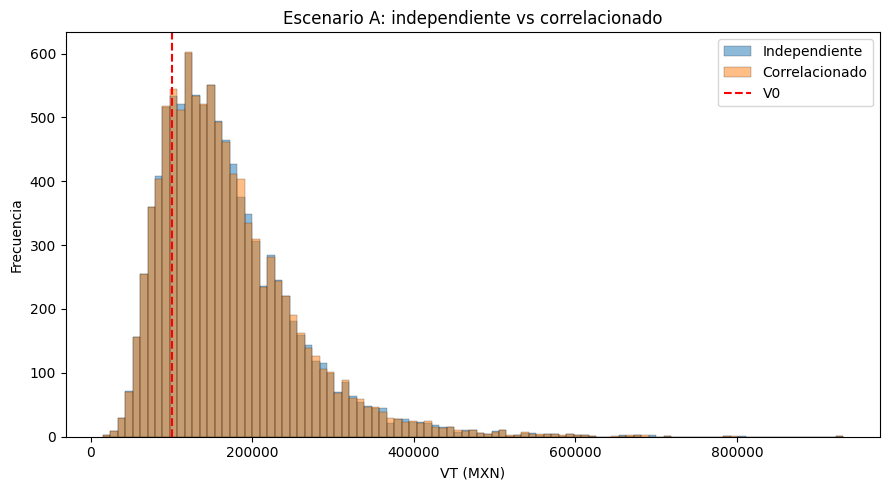

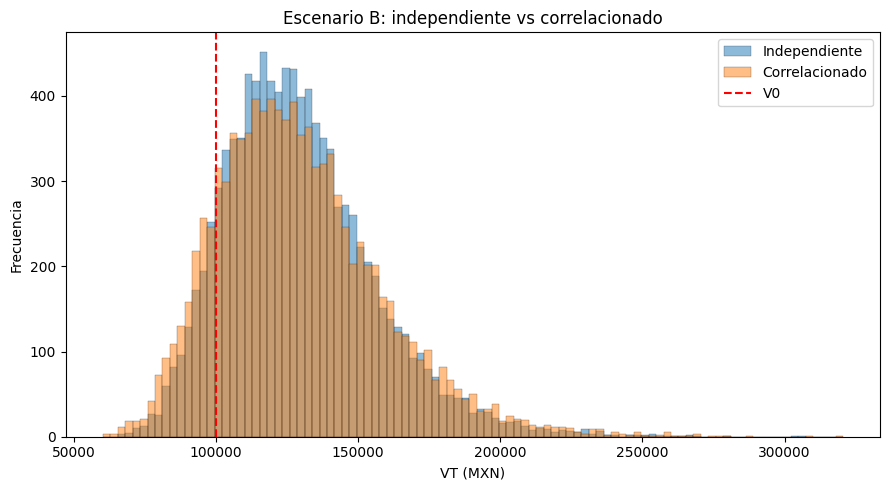

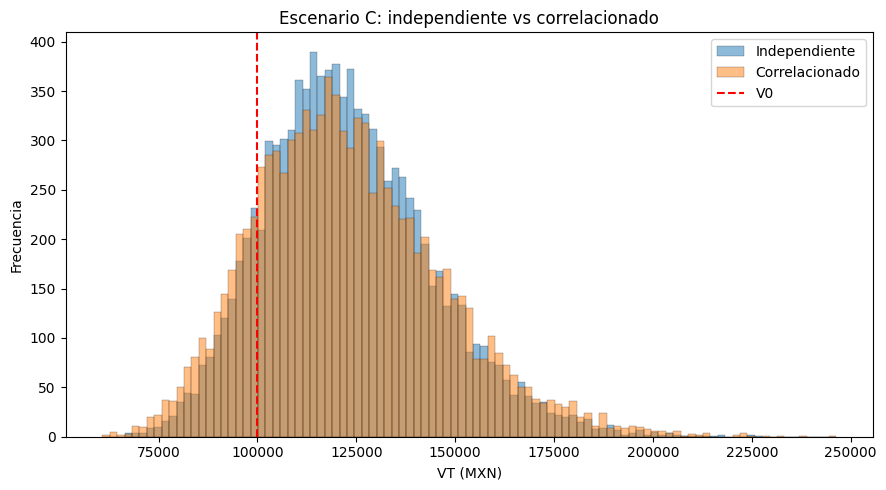

In [10]:
for nombre in escenarios_A:
    graficar_comparacion(VT_ind_A[nombre], VT_corr_A[nombre], V0, f"Escenario {nombre}: independiente vs correlacionado")

Al incluir la correlación, las ganancias promedio prácticamente no cambian, pero el riesgo aumenta. Esto se observa en las gráficas, donde las colas se hacen más amplias y aumenta la probabilidad de pérdida. Sin embargo, el efecto es moderado porque los activos tienen correlaciones bajas.

---

### 2. Ejercicio B: AAPL, MSFT y NVDA, independiente vs correlacionado

#### 2.1 Descargar datos históricos (3 años), con T = 1 y M = 10,000

In [11]:
prices_B, mu_B, sigma_B, R_B = obtener_datos(tickers_B)

S0_B = prices_B.iloc[-1].values
prices_B.tail()


Ticker,AAPL,MSFT,NVDA
Date,,,
2026-11-05,344.170013,535.929993,181.600006
2026-11-06,342.369995,530.609985,186.639999
2026-11-09,350.690002,545.179993,178.669998
2026-11-10,348.510010,533.159973,168.889999
2026-11-11,348.510010,533.159973,168.889999


#### 2.2 Estimar μᵢ, σᵢ y la matriz de correlaciones R

In [12]:
parametros_B = pd.DataFrame({
    "Activo": tickers_B,
    "mu": mu_B,
    "sigma": sigma_B
})

display(parametros_B)
display(R_B.round(2))


,Activo,mu,sigma
0,AAPL,0.216938,0.268600
1,MSFT,0.133377,0.263800
2,NVDA,0.418835,0.470942


Ticker,AAPL,MSFT,NVDA
Ticker,,,
AAPL,1.00,0.34,0.27
MSFT,0.34,1.00,0.41
NVDA,0.27,0.41,1.00


#### 2.3 Simular T = 1: independiente vs correlacionado

In [13]:
epsilon_B = generar_epsilon(len(tickers_B), M)

Z_ind_B = epsilon_B
Z_corr_B = correlacionar(epsilon_B, R_B)

ST_ind_B = simular_precios(S0_B, mu_B, sigma_B, T, Z_ind_B)
ST_corr_B = simular_precios(S0_B, mu_B, sigma_B, T, Z_corr_B)


In [18]:
pd.DataFrame(np.corrcoef(Z_corr_B.T), index=tickers_B, columns=tickers_B).round(2)


,AAPL,MSFT,NVDA
AAPL,1.00,0.36,0.27
MSFT,0.36,1.00,0.43
NVDA,0.27,0.43,1.00


#### 2.4 Calcular Nᵢ

In [15]:
Ni_B = {}

for nombre, w in escenarios_B.items():
    Ni_B[nombre] = calcular_Ni(w, V0, S0_B)

pd.DataFrame(Ni_B, index=tickers_B)


,A,B,C
AAPL,286.935804,94.688815,57.387161
MSFT,0.000000,61.895119,37.512193
NVDA,0.000000,201.314466,355.260822


#### 2.5 Calcular Vₜ

In [16]:
VT_ind_B = {}
VT_corr_B = {}

for nombre in escenarios_B:
    VT_ind_B[nombre] = calcular_VT(Ni_B[nombre], ST_ind_B)
    VT_corr_B[nombre] = calcular_VT(Ni_B[nombre], ST_corr_B)

resultados_B = pd.concat({
    "Independiente": tabla_resultados(VT_ind_B, V0),
    "Correlacionado": tabla_resultados(VT_corr_B, V0)
})

resultados_B.round(4)


VT promedio  Desviación estándar  Percentil 5%  \
Independiente  A  128472.4103           34902.5485    79846.0028   
               B  138917.2511           32456.6255    95861.0648   
               C  150809.0130           51192.3863    88992.1792   
Correlacionado A  128472.4103           34902.5485    79846.0028   
               B  138880.2044           39177.1502    87037.7861   
               C  150752.9940           55245.0279    82574.6519   

                  Percentil 95%  P(VT < V0)  
Independiente  A    192704.2348      0.2105  
               B    197585.0527      0.0762  
               C    247509.5853      0.1163  
Correlacionado A    192704.2348      0.2105  
               B    211473.0139      0.1407  
               C    254312.7091      0.1554

#### 2.6 Histogramas: independiente vs correlacionado (escenarios A, B y C)

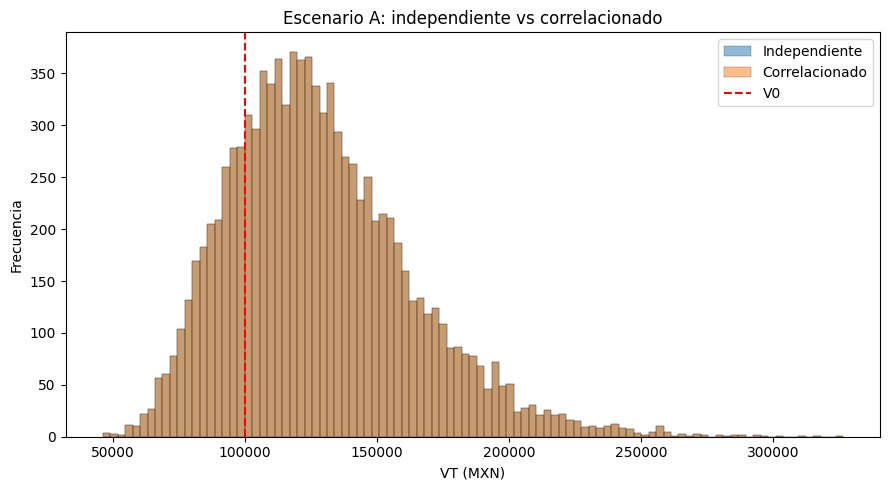

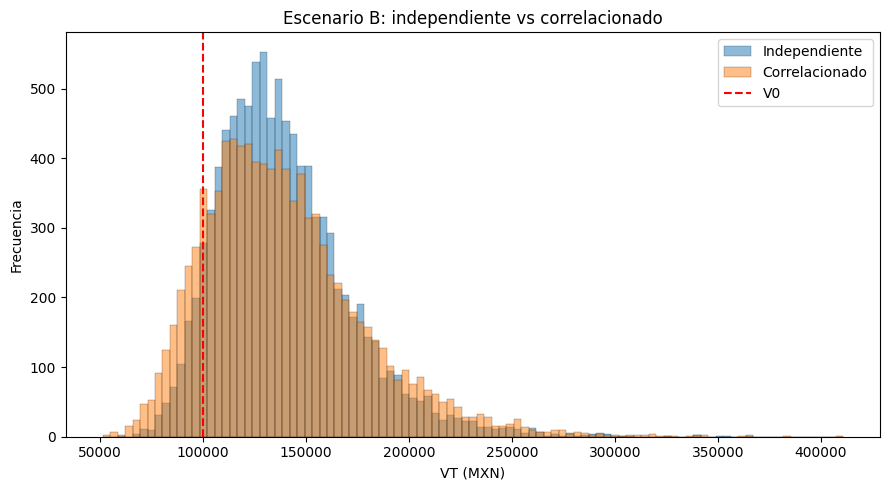

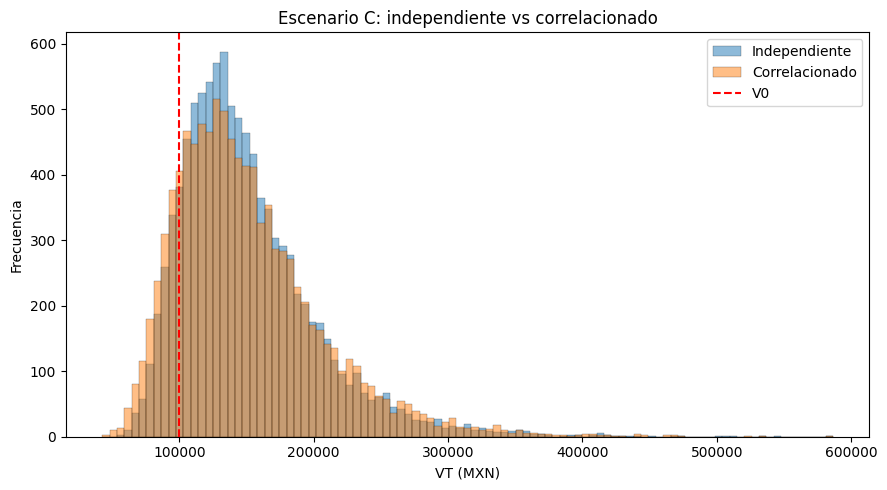

In [17]:
for nombre in escenarios_B:
    graficar_comparacion(VT_ind_B[nombre], VT_corr_B[nombre], V0, f"Escenario {nombre}: independiente vs correlacionado")


En este ejercicio la correlación tiene un mayor impacto porque los tres activos pertenecen al sector tecnológico. Las colas de las gráficas se amplían más, aumentando la dispersión y la probabilidad de pérdida. El escenario con mayor peso en NVDA presenta las mayores ganancias promedio, pero también el mayor riesgo.

---

#### Conclusión 

En ambos ejercicios se observa que considerar la correlación es importante, ya que permite estimar mejor el riesgo del portafolio. Aunque el rendimiento promedio casi no cambia, las pérdidas potenciales pueden ser mayores al considerar que los activos se mueven juntos, por lo que al hacer este proceso nos ayuda a la toma de decisiones de los distintos escenarios.